In [37]:
import os
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image
import random
from collections import Counter, defaultdict
import hashlib
import shutil

In [3]:
data_path = Path("../data/raw/image")

In [4]:
for folder in data_path.iterdir():
    if folder.is_dir():
        images = list(folder.glob("*"))
        print(f"{folder.name}: {len(images)} images")

ASCUS: 782 images
HSIL: 1583 images
LSIL: 1339 images
NILM: 2101 images
SCC: 462 images


In [5]:
# Lets understand the class distribution.

class_counts = {
    "ASCUS": 782,
    "HSIL": 1583,
    "LSIL": 1339,
    "NILM": 2101,
    "SCC": 462
}

dist_df = pd.DataFrame(
    class_counts.items(),
    columns=['Class', 'Image_count']
)

dist_df

,Class,Image_count
0,ASCUS,782
1,HSIL,1583
2,LSIL,1339
3,NILM,2101
4,SCC,462


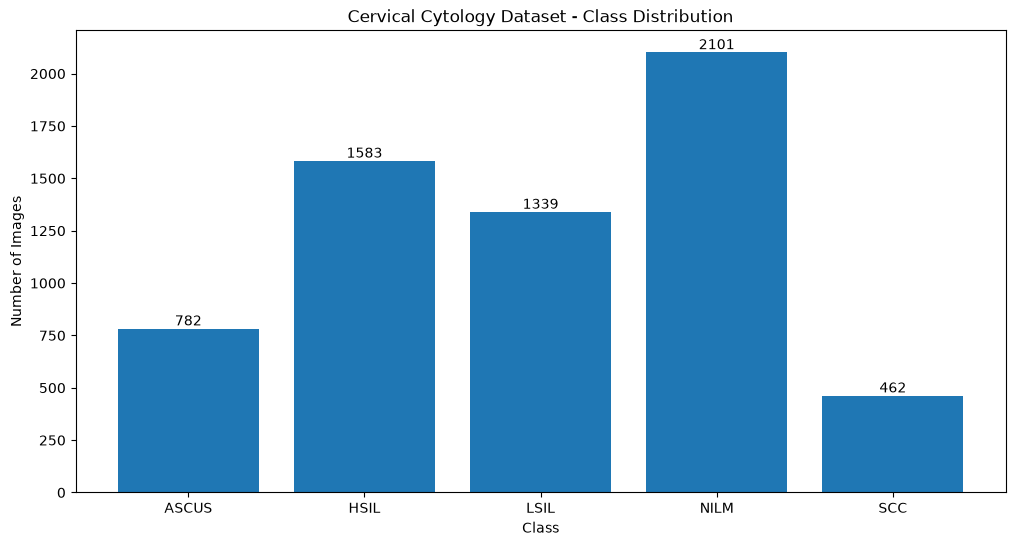

In [6]:
# Lets visualize it.

plt.figure(figsize=(12,6))

ax = plt.bar(dist_df['Class'], dist_df['Image_count'])

plt.bar_label(ax)

plt.title("Cervical Cytology Dataset - Class Distribution")
plt.xlabel("Class")
plt.ylabel("Number of Images")

plt.show()

Our Dataset appears to be imbalanced. 

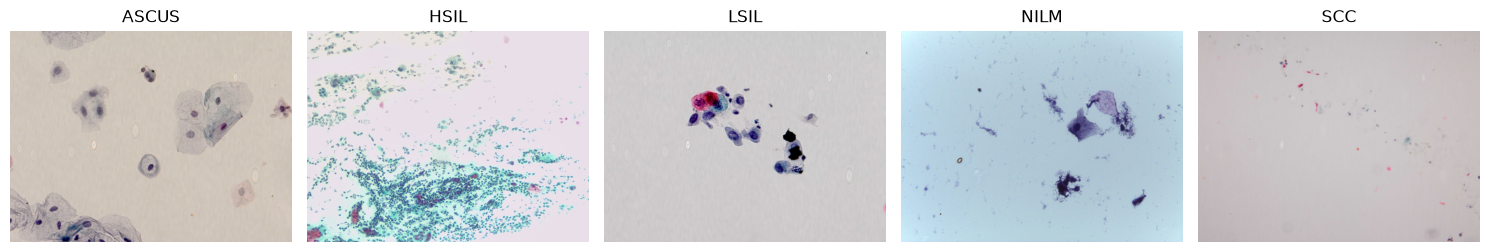

In [7]:
classes = ['ASCUS', 'HSIL', "LSIL", "NILM", "SCC"]

plt.figure(figsize=(15,8))

for i, class_name in enumerate(classes):

    folder = data_path / class_name

    image_files = list(folder.glob("*.jpg"))

    image_path = random.choice(image_files)

    img = Image.open(image_path)

    plt.subplot(1, 5, i+1)
    plt.imshow(img)

    plt.title(class_name)
    plt.axis("off")

plt.tight_layout()
plt.show()


In [8]:
image_sizes = []

for class_name in classes:

    folder = data_path/class_name

    for image_path in folder.glob("*.jpg"):
        with Image.open(image_path) as img:
            image_sizes.append(img.size)


size_counts = Counter(image_sizes)

print("Unique Image Dimensions: ", len(size_counts))

for size, count in size_counts.most_common(10):
    print(f"{size}: {count} Images")

Unique Image Dimensions:  4
(2592, 1944): 2692 Images
(2560, 1920): 1622 Images
(2048, 1536): 962 Images
(1654, 2338): 50 Images


In [9]:
# Lets check the formats of the images:

image_modes = Counter()

for class_name in classes:

    folder = data_path/class_name

    for image_path in folder.rglob("*.jpg"):
        with Image.open(image_path) as img:
            image_modes[img.mode] += 1


print(image_modes)

Counter({'RGB': 5326})


In [10]:
from collections import Counter

extensions = Counter()

for class_name in classes:
    folder = data_path / class_name

    for image_path in folder.rglob("*"):
        if image_path.is_file():
            extensions[image_path.suffix.lower()] += 1

print(extensions)

Counter({'.jpg': 5326, '.png': 941})


In [11]:
# There are two different Image formats here

image_sizes = Counter()
image_modes = Counter()

for class_name in classes:

    folder = data_path/class_name

    for image_path in folder.rglob("*"):

        if image_path.suffix.lower() in [".jpg", '.png', '.jpeg']:

            try: 
                with Image.open(image_path) as img:
                    image_sizes[img.size] += 1
                    image_modes[img.mode] += 1

            except Exception as e:
                print("Error: ", image_path, e)

print("Image Dimensions")
print(image_sizes)

print("\nImage Modes:")
print(image_modes)

Image Dimensions
Counter({(2592, 1944): 2692, (2560, 1920): 1622, (2048, 1536): 962, (1024, 1024): 941, (1654, 2338): 50})

Image Modes:
Counter({'RGB': 6267})


In [12]:
# Lets verify if all the images are valid and not corrupt

corrupted_images = []

for class_name in classes:

    folder = data_path/class_name

    for image_path in folder.glob("*"):

        if image_path.suffix.lower() in [".jpg", ".jpeg", "*png"]:

            try:
                with Image.open(image_path) as img:
                    img.verify()

            except:
                corrupted_images.append(image_path)

print("Total Corrupted Images: ", len(corrupted_images))
    

Total Corrupted Images:  0


In [15]:
# Lets perform a label integrity check

expected_classes = {"ASCUS","HSIL","LSIL","NILM","SCC"}

actual_classes = {
    folder.name for folder in data_path.iterdir() if folder.is_dir()
}

print("Missing Classes: ", expected_classes - actual_classes)
print("Unexpected Classes: ", actual_classes - expected_classes)

Missing Classes:  set()
Unexpected Classes:  set()


In [18]:
# Checking for Duplicate Images

# We check for duplicate images using a hash function

def calculate_hash(image_path):

    with open(image_path, "rb") as f:
        return hashlib.md5(f.read()).hexdigest() # Create a hexadecimal value for the hash


# We will group images based on their hash

hash_groups = defaultdict(list)

for class_name in classes:
    folder = data_path/class_name

    for image_path in folder.glob("*"):
        if image_path.is_file() and image_path.suffix.lower() in [".jpg", '.png', '.jpeg']:
            file_hash = calculate_hash(image_path)

            hash_groups[file_hash].append(image_path)

In [20]:
duplicates = {
    file_hash: paths
    for file_hash, paths in hash_groups.items()
    if len(paths) > 1
}

In [22]:
# Examine the results

print("Duplicate Groups: ", len(duplicates))

for file_hash, paths in duplicates.items():

    print("\nDuplicate Group")

    for path in paths:
        print(path)

Duplicate Groups:  304

Duplicate Group
..\data\raw\image\ASCUS\ASC-US_112.jpg
..\data\raw\image\NILM\NILM_301.jpg

Duplicate Group
..\data\raw\image\ASCUS\ASC-US_113.jpg
..\data\raw\image\NILM\NILM_480.jpg

Duplicate Group
..\data\raw\image\ASCUS\ASC-US_117.jpg
..\data\raw\image\ASCUS\ASC-US_264.jpg
..\data\raw\image\ASCUS\ASC-US_364.jpg
..\data\raw\image\NILM\NILM_1062.jpg
..\data\raw\image\NILM\NILM_500.jpg

Duplicate Group
..\data\raw\image\ASCUS\ASC-US_118.jpg
..\data\raw\image\ASCUS\ASC-US_188.jpg
..\data\raw\image\ASCUS\ASC-US_420.jpg

Duplicate Group
..\data\raw\image\ASCUS\ASC-US_119.jpg
..\data\raw\image\ASCUS\ASC-US_197.jpg

Duplicate Group
..\data\raw\image\ASCUS\ASC-US_120.jpg
..\data\raw\image\ASCUS\ASC-US_192.jpg

Duplicate Group
..\data\raw\image\ASCUS\ASC-US_121.jpg
..\data\raw\image\ASCUS\ASC-US_196.jpg

Duplicate Group
..\data\raw\image\ASCUS\ASC-US_122.jpg
..\data\raw\image\NILM\NILM_1080.jpg
..\data\raw\image\NILM\NILM_513.jpg

Duplicate Group
..\data\raw\image\ASC

In [24]:
# Total Duplicates present

total_duplicate_files = sum(
    len(paths) for paths in duplicates.values()
)

print(total_duplicate_files)

893


In [25]:
# Number of redundant copies

redundant_files = sum(
    len(paths) - 1 for paths in duplicates.values()
)

print(redundant_files)

589


In [27]:
# Duplicates in Same class vs Cross-class duplicates

within_class_groups = 0
cross_class_groups = 0

for paths in duplicates.values():

    group_classes = {
        path.parent.name for path in paths
    }

    if len(group_classes) == 1:
        within_class_groups += 1
    else:
        cross_class_groups += 1

print("Within Class Groups: ", within_class_groups)
print("Cross-Class Groups: ", cross_class_groups)

Within Class Groups:  192
Cross-Class Groups:  112


Now we have within class duplicates which can be handled by deleted the duplicates and keeping only one copy. The cross-class duplicates must be held back until proper information on them is recieved. So we will create a clean dataset by dropping the cross class duplicates entirely and dropping the same class duplicates but keeping 1.

For that we will create a dataset cleaning manifest.

In [28]:
# Cleaning Operation

# Store cleaning Decisions
cleaning_records = []

# Track Images That belong to duplicate Groups
duplicate_paths = set()

# Process Every Duplicate Group
for group_id, (file_hash, paths) in enumerate(duplicates.items(), start=1):

  # Identify the classes present in this group
  group_classes = {path.parent.name for path in paths}

  # Case 1: Cross-Class duplicates
  if len(group_classes) > 1:

    for path in paths:

      duplicate_paths.add(path)

      cleaning_records.append({
          "group_id": group_id,
          "file_hash": file_hash,
          "source_path": str(path),
          "class": path.parent.name,
          "action": "QUARANTINE",
          "reason": "Cross-class label conflict"
      })

  # Case 2: Within Class Duplicates
  else:

    # Sort to select a deterministic representative
    sorted_paths = sorted(paths)

    for index,path in enumerate(sorted_paths):

      duplicate_paths.add(path)

      if index == 0:
        action = "KEEP"
        reason = "Representative Image"
      else:
        action = "EXCLUDE"
        reason = "Within-Class Redundant Copy"

      cleaning_records.append({
                "group_id": group_id,
                "file_hash": file_hash,
                "source_path": str(path),
                "class": path.parent.name,
                "action": action,
                "reason": reason
            })

In [29]:
# We include images which do not have duplicates

for class_name in classes:

    folder = data_path / class_name

    for image_path in folder.glob("*"):

        if (
            image_path.is_file()
            and image_path.suffix.lower() in ['.jpg','.png','.jpeg']
            and image_path not in duplicate_paths
        ):

            cleaning_records.append({
                "group_id": None,
                "file_hash": None,
                "source_path": str(image_path),
                "class": class_name,
                "action": "KEEP",
                "reason": "Unique image"
            })

In [30]:
cleaning_df = pd.DataFrame(cleaning_records)

print(cleaning_df.shape)

cleaning_df.head()

(6267, 6)


,group_id,file_hash,source_path,class,action,reason
0,1.0,5904245afeb0f067ab4bd654f4c7645b,..\data\raw\image\ASCUS\ASC-US_112.jpg,ASCUS,QUARANTINE,Cross-class label conflict
1,1.0,5904245afeb0f067ab4bd654f4c7645b,..\data\raw\image\NILM\NILM_301.jpg,NILM,QUARANTINE,Cross-class label conflict
2,2.0,53e17624c6f7a1bf11902cb00f76b5fe,..\data\raw\image\ASCUS\ASC-US_113.jpg,ASCUS,QUARANTINE,Cross-class label conflict
3,2.0,53e17624c6f7a1bf11902cb00f76b5fe,..\data\raw\image\NILM\NILM_480.jpg,NILM,QUARANTINE,Cross-class label conflict
4,3.0,858a62bb34927557c0bdb66739872cd8,..\data\raw\image\ASCUS\ASC-US_117.jpg,ASCUS,QUARANTINE,Cross-class label conflict


In [31]:
print(cleaning_df["action"].value_counts())

action
KEEP          5566
QUARANTINE     371
EXCLUDE        330
Name: count, dtype: int64


In [32]:
pd.crosstab(
    cleaning_df["class"],
    cleaning_df["action"]
)

action,EXCLUDE,KEEP,QUARANTINE
class,,,
ASCUS,38,645,99
HSIL,68,1442,73
LSIL,30,1230,79
NILM,193,1790,118
SCC,1,459,2


In [36]:
# We will copy the images based on the action that we specified for it.

# Original Dataset
data_path = Path("../data/raw/image")

# New Cleaned Dataset
working_path = Path("../data/processed/cleaned_data")

# Quarantined Images
quarantine_path = Path("../data/processed/quarantine_data")

# Audit reports:
reports_path = Path("../data/processed/reports")

# Create directories
for folder in [working_path, reports_path]:
  folder.mkdir(parents=True, exist_ok=True)

# Create five class folders in working directory
for class_name in classes:
  (working_path / class_name).mkdir(exist_ok=True)
  (quarantine_path / class_name).mkdir(exist_ok=True)

print("Directory Structure Created.")


Directory Structure Created.


In [38]:
# We will copy the images based on the manifest that we created using shutil

for _,row in cleaning_df.iterrows():

  source = Path(row['source_path'])
  action = row['action']
  class_name = row['class']

  if action == "KEEP":

    destination = working_path / class_name / source.name

  elif action == "QUARANTINE":

    destination = quarantine_path / class_name / source.name
   
  else:

    continue

  shutil.copy2(source,destination)

print("Cleaned Dataset Construction Completed.")


Cleaned Dataset Construction Completed.


In [39]:
# Validating the cleaned dataset

for class_name in classes:

    folder = working_path / class_name

    image_count = sum(
        1 for path in folder.iterdir()
        if path.is_file() and path.suffix.lower() in ['.jpg','.png', '.jpeg']
    )

    print(f"{class_name}: {image_count}")

ASCUS: 645
HSIL: 1442
LSIL: 1230
NILM: 1790
SCC: 459


In [40]:
# Save the cleaning manifest

cleaning_df.to_csv(
    reports_path / "cleaning_manifest.csv",
    index=False
)

print("Cleaning Manifest Saved.")

Cleaning Manifest Saved.


Data Audit Is complete.